# Duality and Post-Optimal Analysis

This notebook formulates primal and dual linear programs, checks their mathematical relationships, and evaluates changes to an existing optimal plan. The applications involve paint production and three-operation toy assembly. All monetary values, resource units, and decision variables are identified within each example.

**Contents:** Dual construction; primal–dual feasibility and complementary slackness; basis-inverse calculations; economic interpretation; dual Simplex; generalized Simplex decision rules; changes to resource capacities; added constraints; revised prices; and new production activities.

## 1. Python setup

**Tools:** `scipy.optimize.linprog` (HiGHS) provides verified primal and dual solutions, including constraint marginals. NumPy provides basis matrix calculations; Pandas displays intermediate calculations; Matplotlib generates engineering charts. An explicit small-tableau implementation illustrates dual Simplex pivots because production-grade solvers do not expose pedagogical tableaux.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display
pd.set_option('display.precision', 5)
np.set_printoptions(precision=5, suppress=True)

def solve_max(c, A, b, Aeq=None, beq=None, bounds=None):
    return linprog(-np.asarray(c, dtype=float), A_ub=np.asarray(A,dtype=float) if A is not None else None,
                   b_ub=np.asarray(b,dtype=float) if b is not None else None,
                   A_eq=np.asarray(Aeq,dtype=float) if Aeq is not None else None,
                   b_eq=np.asarray(beq,dtype=float) if beq is not None else None,
                   bounds=(0,None) if bounds is None else bounds, method='highs-ds')

def report(res, names):
    print('Solver:',res.message)
    if res.success:
        display(pd.DataFrame({'Variable':names, 'Optimal value':res.x}))
        print('Optimal objective (max):',round(-res.fun,6))
        if len(res.ineqlin.residual):
            display(pd.DataFrame({'Capacity slack':res.ineqlin.residual,
                                  'Max objective marginal':-res.ineqlin.marginals}))

## 2. Primal and dual formulation — paint production

### Problem description

A manufacturer produces exterior and interior paints using two raw materials. One ton of exterior paint earns $5,000 and consumes 6 tons of material M1 and 1 ton of M2. One ton of interior paint earns $4,000 and uses 4 tons of M1 and 2 tons of M2. Daily supplies are 24 tons of M1 and 6 tons of M2. Interior production cannot exceed exterior production by more than 1 ton, and at most 2 tons of interior paint may be produced.

The decision is how many tons of each paint to produce daily to maximize total profit.

Let $x_1$ denote exterior paint (tons/day), $x_2$ interior paint (tons/day), and $z$ daily profit (thousands of dollars).

### Complete primal model

$$
\max z=5x_1+4x_2
$$

subject to

$$
\begin{aligned}
6x_1+4x_2 &\leq24 &&\text{(M1, tons/day)}\\
x_1+2x_2 &\leq6 &&\text{(M2, tons/day)}\\
-x_1+x_2 &\leq1 &&\text{(market balance)}\\
x_2 &\leq2 &&\text{(interior demand)}\\
x_1,x_2 &\geq0.
\end{aligned}
$$

The corresponding dual assigns an implicit value $y_i$ to one additional unit of the right-hand-side resource or limit. For a maximization LP with $Ax\leq b$, $x\geq0$, its dual is a minimization LP with $A^Ty\geq c$, $y\geq0$.

### Complete dual model

$$
\min w=24y_1+6y_2+y_3+2y_4
$$

subject to

$$
\begin{aligned}
6y_1+y_2-y_3 &\geq5 &&\text{(exterior contribution)}\\
4y_1+2y_2+y_3+y_4 &\geq4 &&\text{(interior contribution)}\\
y_1,y_2,y_3,y_4 &\geq0.
\end{aligned}
$$

The dual prices $y_1,y_2$ have units of thousands of dollars per additional ton of raw material; $y_3,y_4$ price changes to the two market limits, measured in tons of paint.

In [2]:
c_paint=np.array([5.,4.]); A_paint=np.array([[6,4],[1,2],[-1,1],[0,1]],float)
b_paint=np.array([24.,6.,1.,2.])
pr=solve_max(c_paint,A_paint,b_paint)
assert pr.success
report(pr,['Exterior (tons/day)','Interior (tons/day)'])
y=-pr.ineqlin.marginals
print('Dual price vector:',y)
print('Dual value:',b_paint@y,'Primal value:',-pr.fun)
print('Primal-dual gap:',abs(b_paint@y+pr.fun))
assert np.all(A_paint.T@y>=c_paint-1e-8)
assert np.isclose(b_paint@y,-pr.fun)

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Variable,Optimal value
0,Exterior (tons/day),3.0
1,Interior (tons/day),1.5


Optimal objective (max): 21.0


,Capacity slack,Max objective marginal
0,0.0,0.75
1,0.0,0.50
2,2.5,0.00
3,0.5,0.00


Dual price vector: [0.75 0.5  0.   0.  ]
Dual value: 21.0 Primal value: 21.0
Primal-dual gap: 0.0


**Interpretation.** The recommended production mix is 3 tons/day of exterior paint and 1.5 tons/day of interior paint, earning $21,000/day. Both raw-material constraints are binding. The limits on interior production and market balance have positive slack, so their local dual prices are zero in this nondegenerate optimum. The equality of primal and dual objectives numerically confirms strong duality.

## 3. Dual construction with equality constraints and unrestricted prices

### Problem description

A three-activity system earns $5, $12, and $4 per activity unit. The first resource has capacity 10 and the second operating requirement must equal exactly 8. Determine the maximum contribution.

$$
\begin{aligned}
\max z&=5x_1+12x_2+4x_3\\
x_1+2x_2+x_3&\leq10\\
2x_1-x_2+3x_3&=8\\
x_1,x_2,x_3&\geq0.
\end{aligned}
$$

Because the second primal constraint is an equality, its dual price $y_2$ is unrestricted in sign. The first dual variable remains nonnegative.

$$
\begin{aligned}
\min w &=10y_1+8y_2\\
y_1+2y_2&\geq5\\
2y_1-y_2&\geq12\\
y_1+3y_2&\geq4\\
y_1&\geq0,\quad y_2\in\mathbb{R}.
\end{aligned}
$$

An unrestricted primal variable would, conversely, yield an equality dual constraint.

In [3]:
mix=linprog([-5,-12,-4], A_ub=[[1,2,1]],b_ub=[10], A_eq=[[2,-1,3]],b_eq=[8],bounds=(0,None),method='highs-ds')
assert mix.success
print('Primal activity levels:',mix.x,'Max value:',-mix.fun)
print('Dual prices for capacity and equality:',-mix.ineqlin.marginals,-mix.eqlin.marginals)
du=linprog([10,8], A_ub=[[-1,-2],[-2,1],[-1,-3]], b_ub=[-5,-12,-4],bounds=[(0,None),(None,None)],method='highs-ds')
assert du.success
print('Dual variable values:',du.x,'Min value:',du.fun)
assert np.isclose(-mix.fun,du.fun)

Primal activity levels: [5.2 2.4 0. ] Max value: 54.8
Dual prices for capacity and equality: [5.8] [-0.4]
Dual variable values: [ 5.8 -0.4] Min value: 54.8


## 4. Weak/strong duality, slacks, and complementary slackness

For any primal-feasible $x$ and dual-feasible $y$ in a max–min pair:

$$
c^Tx\leq b^Ty.
$$

At optimality, equality holds:

$$
c^Tx^*=b^Ty^*.
$$

For each resource constraint $i$ and activity $j$, complementary slackness states:

$$
\begin{aligned}
y_i^*(b_i-a_i^Tx^*)&=0,\\
x_j^*((A^Ty^*)_j-c_j)&=0.
\end{aligned}
$$

A positive capacity slack therefore forces its dual price to zero. A positive activity can be used only when its dual opportunity cost equals its original unit contribution. The converse need not hold when degeneracy or alternative optima occur.

In [4]:
p_slack=b_paint-A_paint@pr.x
d_slack=A_paint.T@y-c_paint
print('Primal slack:',p_slack)
print('Dual slack (opportunity cost minus profit):',d_slack)
print('Resource complementary products:',y*p_slack)
print('Activity complementary products:',pr.x*d_slack)
assert np.allclose(y*p_slack,0,atol=1e-8)
assert np.allclose(pr.x*d_slack,0,atol=1e-8)

Primal slack: [0.  0.  2.5 0.5]
Dual slack (opportunity cost minus profit): [0. 0.]
Resource complementary products: [0. 0. 0. 0.]
Activity complementary products: [0. 0.]


## 5. Simplex basis, inverse matrix, reduced costs, and dual prices

### Problem description

Using the optimal paint-production mix, determine its basic variables and recover the shadow prices directly from the optimal basis rather than treating the solver marginals as unexplained output.

Add slack variables $s_1,\ldots,s_4\geq0$:

$$
\begin{aligned}
6x_1+4x_2+s_1&=24\\
x_1+2x_2+s_2&=6\\
-x_1+x_2+s_3&=1\\
x_2+s_4&=2.
\end{aligned}
$$

At the optimum, the basis is $(x_1,x_2,s_3,s_4)$. For standard-form constraint matrix $\bar A=[A\ I]$, the basic solution is $x_B=B^{-1}b$. Basic objective coefficients $c_B$ give the dual vector $y^T=c_B^TB^{-1}$. Reduced costs for a maximization model are

$$
\bar c_j=c_j-y^T\bar a_j\leq0\quad\text{at an optimal basis}.
$$

In [5]:
Abar=np.column_stack([A_paint,np.eye(4)])
all_names=['x1','x2','s1','s2','s3','s4']; cb_all=np.r_[c_paint,np.zeros(4)]
basis=[0,1,4,5]; B=Abar[:,basis]; Binv=np.linalg.inv(B)
xb=Binv@b_paint; y_from_basis=cb_all[basis]@Binv
reduced=cb_all-y_from_basis@Abar
print('Basis B:');display(pd.DataFrame(B,index=['C1','C2','C3','C4'],columns=[all_names[i] for i in basis]))
print('Inverse of basis:');display(pd.DataFrame(Binv))
print('Basic quantities:');display(pd.DataFrame({'Basic variable':[all_names[i] for i in basis],'Value':xb}))
print('Dual prices from basis:',y_from_basis)
print('Reduced costs:',dict(zip(all_names,reduced.round(6))))
assert np.allclose(y_from_basis,y)
assert np.max(reduced)<=1e-8

Basis B:


,x1,x2,s3,s4
C1,6.0,4.0,0.0,0.0
C2,1.0,2.0,0.0,0.0
C3,-1.0,1.0,1.0,0.0
C4,0.0,1.0,0.0,1.0


Inverse of basis:


,0,1,2,3
0,0.250,-0.50,0.0,0.0
1,-0.125,0.75,0.0,0.0
2,0.375,-1.25,1.0,-0.0
3,0.125,-0.75,0.0,1.0


Basic quantities:


,Basic variable,Value
0,x1,3.0
1,x2,1.5
2,s3,2.5
3,s4,0.5


Dual prices from basis: [0.75 0.5  0.   0.  ]
Reduced costs: {'x1': np.float64(0.0), 'x2': np.float64(0.0), 's1': np.float64(-0.75), 's2': np.float64(-0.5), 's3': np.float64(0.0), 's4': np.float64(0.0)}


**Interpretation.** $B^{-1}$ describes how basic production and slack values respond to small changes in constraint right-hand sides. Reduced costs quantify the profit improvement available from introducing a currently nonbasic variable; a negative reduced cost in this maximization convention means forcing that variable positive locally would reduce profit under the present basis.

## 6. Economic meaning of dual prices and reduced costs

For the paint manufacturer, the dual resource prices answer a purchasing question: what is the largest incremental amount it can rationally pay for a small additional unit of material, assuming the current model, production prices, and local basis remain valid? A zero dual price is *local* and does not mean the corresponding resource or limit can never matter.

The plot compares available, consumed, and unused capacities. Each resource has a different physical scale; the percentages therefore compare utilization rather than raw material quantities.

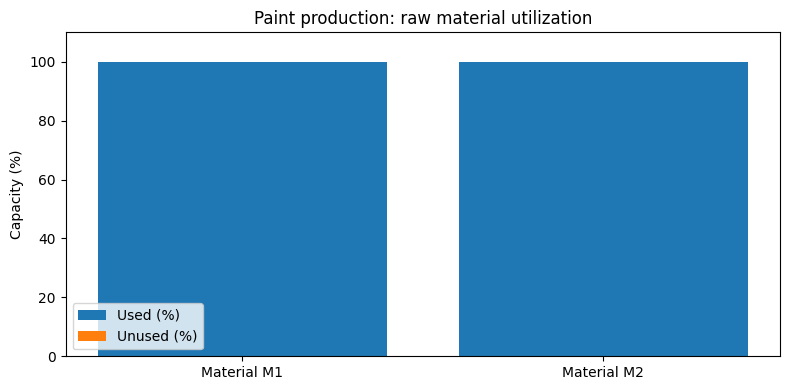

Marginal value of M1 ($/ton): 750.0 M2 ($/ton): 500.0


In [6]:
usage=A_paint[:2]@pr.x; capacities=b_paint[:2]
fig,ax=plt.subplots(figsize=(8,4))
xloc=np.arange(2)
ax.bar(xloc,100*usage/capacities,label='Used (%)')
ax.bar(xloc,100*(capacities-usage)/capacities,bottom=100*usage/capacities,label='Unused (%)')
ax.set_xticks(xloc,['Material M1','Material M2']);ax.set_ylabel('Capacity (%)');ax.set_ylim(0,110)
ax.set_title('Paint production: raw material utilization');ax.legend();plt.tight_layout();plt.show()
print('Marginal value of M1 ($/ton):',1000*y[0], 'M2 ($/ton):',1000*y[1])

## 7. Dual Simplex — worked iteration with an infeasible RHS

### Problem description

A plant has the same activities and unit profits as the small model below, but an updated resource requirement makes the current tableau infeasible while its reduced costs remain dual-feasible. Dual Simplex restores feasibility while keeping the objective row optimal at every pivot.

Consider

$$
\begin{aligned}
\max z&=-x_1-x_2\\
-x_1-x_2&\leq-2\\
-x_1&\leq-1\\
x_1,x_2&\geq0.
\end{aligned}
$$

Equivalently, minimize $x_1+x_2$ subject to $x_1+x_2\geq2$ and $x_1\geq1$. The all-slack tableau has a nonpositive objective row but negative basic RHS entries. The dual pivot rule chooses a row with negative RHS and a nonbasic column that preserves nonnegative coefficients in the $z-c$ row.

For a tableau whose top row is $z-c\geq0$, with leaving row $r$ and $b_r<0$, eligible entering columns have $a_{rj}<0$ and the ratio is

$$
\theta_j=\frac{(z_j-c_j)}{-a_{rj}}.
$$

Choose the smallest eligible ratio; pivot using Gauss–Jordan operations. The next code displays the complete tableau before and after each pivot.

### Explicit first pivot calculation

Initially, with $x_1=x_2=0$, the slack basis has $s_1=-2$ and $s_2=-1$; hence the tableau is primal-infeasible. The objective equation $z+x_1+x_2=0$ has the maximization-form $z_j-c_j$ values $(1,1)$, satisfying dual feasibility.

The most negative RHS selects row $s_1$ to leave. Both $x_1$ and $x_2$ have coefficient $-1$ in that row, so their dual ratios are

$$
\theta_{x_1}=\frac{1}{-(-1)}=1,\qquad \theta_{x_2}=\frac{1}{-(-1)}=1.
$$

Choosing $x_1$ to enter, the pivot is $-1$. Divide the $s_1$ row by $-1$, then eliminate $x_1$ from every other row:

$$
\begin{aligned}
R_{x_1}^{\mathrm{new}}&=R_{s_1}^{\mathrm{old}}/(-1),\\
R_z^{\mathrm{new}}&=R_z^{\mathrm{old}}-R_{x_1}^{\mathrm{new}},\\
R_{s_2}^{\mathrm{new}}&=R_{s_2}^{\mathrm{old}}+R_{x_1}^{\mathrm{new}}.
\end{aligned}
$$

The resulting basic values are $x_1=2$ and $s_2=1$, with $x_2=s_1=0$. All are nonnegative, and the objective value is $z=-2$. The alternative pivot $x_2$ would require an additional feasibility check because the other row still has a negative RHS.

In [7]:
def trace_dual_simplex(T,names,basic,max_iter=20):
    T=np.asarray(T,float).copy();basic=list(basic);hist=[]
    for k in range(max_iter+1):
        print(f'Iteration {k}:')
        df=pd.DataFrame(T,columns=names+['RHS'],index=['z']+basic);display(df.round(5))
        if np.all(T[1:,-1]>=-1e-9):
            print('Primal feasible and dual optimal; finished.')
            return T,basic,hist
        candidates=np.where(T[1:,-1]<-1e-9)[0]
        r=1+int(candidates[np.argmin(T[1:,-1][candidates])]); eligible=np.where(T[r,:-1]<-1e-9)[0]
        if len(eligible)==0:raise ValueError('Infeasible: no entering column for negative RHS')
        ratios=T[0,eligible]/(-T[r,eligible]); j=int(eligible[np.argmin(ratios)])
        print('Leaving:',basic[r-1], 'RHS:',T[r,-1]);print('Entering candidates:',[(names[e],round(float(v),5)) for e,v in zip(eligible,ratios)])
        print('Pivot:',names[j],'enters; element',T[r,j])
        hist.append((basic[r-1],names[j],float(T[r,j])))
        T[r]=T[r]/T[r,j]
        for i in range(T.shape[0]):
            if i!=r:T[i]-=T[i,j]*T[r]
        basic[r-1]=names[j]
    raise RuntimeError('Iteration limit')
# z + x1 + x2 = 0; -x1-x2+s1=-2; -x1+s2=-1
T=np.array([[1,1,0,0,0],[-1,-1,1,0,-2],[-1,0,0,1,-1]],float)
Td,bd,steps=trace_dual_simplex(T,['x1','x2','s1','s2'],['s1','s2'])
assert np.isclose(Td[0,-1],-2)
assert np.all(Td[1:,-1]>=-1e-9)
res_ds=solve_max([-1,-1],[[-1,-1],[-1,0]],[-2,-1]);assert res_ds.success
print('HiGHS solution:',res_ds.x, 'Max objective:',-res_ds.fun)

Iteration 0:


,x1,x2,s1,s2,RHS
z,1.0,1.0,0.0,0.0,0.0
s1,-1.0,-1.0,1.0,0.0,-2.0
s2,-1.0,0.0,0.0,1.0,-1.0


Leaving: s1 RHS: -2.0
Entering candidates: [('x1', 1.0), ('x2', 1.0)]
Pivot: x1 enters; element -1.0
Iteration 1:


,x1,x2,s1,s2,RHS
z,0.0,0.0,1.0,0.0,-2.0
x1,1.0,1.0,-1.0,-0.0,2.0
s2,0.0,1.0,-1.0,1.0,1.0


Primal feasible and dual optimal; finished.
HiGHS solution: [2. 0.] Max objective: -2.0


**Interpretation.** The algorithm minimizes total activity output under the lower-bound requirements; the minimum is 2 units, so the maximum of its negative is $-2$ in the chosen objective units. Multiple feasible allocations can achieve this same objective (for example, $x_1=1,x_2=1$ and $x_1=2,x_2=0$). The tableau demonstrates how dual feasibility is maintained as negative RHS values are eliminated.

## 8. Generalized Simplex — when optimality and feasibility both change

When a perturbation violates both primal feasibility (a negative basic value) and dual optimality (an improving reduced cost), neither the standard primal- nor dual-Simplex starting condition holds. A generalized procedure can use additional pivots or a suitable crash/feasibility phase to restore a valid starting basis; production LP solvers handle such reformulations internally.

For an updated model, check explicitly:

$$
\begin{aligned}
x_B'&=B^{-1}b',\\
y'^T&=c_B'^TB^{-1},\\
\bar c_N'&=c_N'-y'^TA_N.
\end{aligned}
$$

If $x_B'\not\geq0$ and some $\bar c_N'>0$ (maximization convention), the former basis satisfies neither test. Re-solving with HiGHS is the dependable computational approach; the next section demonstrates this joint change using the paint-production model.

### Interpreting the feasibility and optimality tests

The basis inverse does not need to be recalculated when only the right-hand-side vector or objective coefficients change. It can be reused to detect the kind of update needed:

| Basic solution test | Reduced-cost test | Next computation |
|---|---|---|
| $x_B\geq0$ | $\bar c_N\leq0$ | Already optimal |
| $x_B\geq0$ | Some $\bar c_N>0$ | Primal Simplex |
| Some $x_B<0$ | $\bar c_N\leq0$ | Dual Simplex |
| Some $x_B<0$ | Some $\bar c_N>0$ | Restore a valid basis and re-optimize (generalized approach) |

These reduced-cost signs apply to **maximization** with $\bar c=c-y^TA$.

## 9. Post-optimal analysis: simultaneous changes in paint resources and profits

### Problem description

Suppose M1 supply increases from 24 to 28 tons/day, M2 supply increases from 6 to 8, exterior unit profit falls from $5,000 to $1,000 per ton, and interior profit remains $4,000 per ton. Determine whether the old production plan stays feasible and optimal, then compute the replacement plan.

The updated objective and capacity restrictions are

$$
\begin{aligned}
\max z' &=x_1+4x_2\\
6x_1+4x_2&\leq28\\
x_1+2x_2&\leq8\\
-x_1+x_2&\leq1\\
x_2&\leq2,\quad x_1,x_2\geq0.
\end{aligned}
$$

We first test the old basis against new RHS and new objective coefficients, then re-optimize.

In [8]:
c_changed=np.array([1.,4.]); b_changed=np.array([28.,8.,1.,2.])
new_basic=Binv@b_changed; y_changed=c_changed@np.linalg.inv(A_paint[:2,:]) if False else np.r_[c_changed,np.zeros(4)][basis]@Binv
rc_changed=np.r_[c_changed,np.zeros(4)]-y_changed@Abar
print('Current basis under modified capacities:',dict(zip([all_names[i] for i in basis],new_basic)))
print('Reduced costs under modified profit:',dict(zip(all_names,rc_changed.round(5))))
print('Current basis feasible?',bool(np.all(new_basic>=-1e-8)))
print('Current basis optimal?',bool(np.all(rc_changed<=1e-8)))
changed=solve_max(c_changed,A_paint,b_changed);assert changed.success
report(changed,['Exterior (tons)','Interior (tons)'])
print('Old profit vector at old x under new unit profits:',c_changed@pr.x)
assert np.all(A_paint@changed.x<=b_changed+1e-7)

Current basis under modified capacities: {'x1': np.float64(3.0), 'x2': np.float64(2.499999999999999), 's3': np.float64(1.5000000000000018), 's4': np.float64(-0.4999999999999991)}
Reduced costs under modified profit: {'x1': np.float64(0.0), 'x2': np.float64(0.0), 's1': np.float64(0.25), 's2': np.float64(-2.5), 's3': np.float64(0.0), 's4': np.float64(0.0)}
Current basis feasible? False
Current basis optimal? False
Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Variable,Optimal value
0,Exterior (tons),3.33333
1,Interior (tons),2.00000


Optimal objective (max): 11.333333


,Capacity slack,Max objective marginal
0,0.00000,0.16667
1,0.66667,0.00000
2,2.33333,0.00000
3,0.00000,3.33333


Old profit vector at old x under new unit profits: 9.0


**Interpretation.** Report the change in exterior/interior output together with the new daily objective. The initial basis feasibility and reduced-cost tests identify *why* continuing the previous production pattern cannot be justified simply from the old optimum.

## 10. TOYCO manufacturing assembly — baseline optimal schedule

### Problem description

An assembly shop makes toy trains, trucks, and cars. Their unit revenues are $3, $2, and $5. Each unit passes through a subset of three operations; daily operation capacities are 430, 460, and 420 minutes. The table displays minutes required per toy type. Determine the highest-revenue product mix.

| Operation | Train $x_1$ | Truck $x_2$ | Car $x_3$ | Daily capacity (min) |
|---|---:|---:|---:|---:|
| 1 | 1 | 2 | 1 | 430 |
| 2 | 3 | 0 | 2 | 460 |
| 3 | 1 | 4 | 0 | 420 |

$$
\begin{aligned}
\max z&=3x_1+2x_2+5x_3\\
x_1+2x_2+x_3&\leq430\\
3x_1+2x_3&\leq460\\
x_1+4x_2&\leq420\\
x_1,x_2,x_3&\geq0.
\end{aligned}
$$

The continuous LP interpretation allows fractional toy outputs if necessary; a true indivisible-unit plan would require an integer model.

In [9]:
At=np.array([[1,2,1],[3,0,2],[1,4,0]],float)
bt=np.array([430.,460.,420.]);ct=np.array([3.,2.,5.])
toy=solve_max(ct,At,bt);assert toy.success
report(toy,['Trains','Trucks','Cars'])
print('Operation utilization (%)',(100*At@toy.x/bt).round(3))
print('Economic values per additional operation-minute:',(-toy.ineqlin.marginals).round(5))
assert np.allclose(toy.x,[0,100,230]);assert np.isclose(-toy.fun,1350)

Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Variable,Optimal value
0,Trains,0.0
1,Trucks,100.0
2,Cars,230.0


Optimal objective (max): 1350.0


,Capacity slack,Max objective marginal
0,0.0,1.0
1,0.0,2.0
2,20.0,0.0


Operation utilization (%) [100.    100.     95.238]
Economic values per additional operation-minute: [1. 2. 0.]


**Interpretation.** Make 100 trucks and 230 cars and no trains for maximum daily revenue $1,350. Operation 1 and operation 2 are fully utilized; operation 3 has 20 unused minutes. Marginal revenue values are $1/minute, $2/minute, and $0/minute, respectively, for locally valid changes to the three operation capacities.

## 11. Post-optimal changes affecting feasibility: RHS updates

The initial TOYCO basis can be taken as $(x_2,x_3,s_3)$. For a resource-capacity change $\Delta b$, the existing basis produces

$$
x_B'=B^{-1}(b+\Delta b).
$$

If the new basic values are nonnegative, the old basis stays feasible; because its objective coefficients are unchanged, it also remains optimal. Otherwise, apply dual Simplex or re-solve. The next cells compare: (A) a capacity addition, (B) transfer of 20 minutes of idle operation 3 time to operation 1, and (C) transfer of 20 minutes to operation 2.

### Basis sensitivity calculations

For the original basic variables $(x_2,x_3,s_3)$, the optimal basis inverse is

$$
B^{-1}=\begin{bmatrix}0.5&-0.25&0\\0&0.5&0\\-2&1&1\end{bmatrix}.
$$

Consequently, for a simultaneous change $\Delta b=(\Delta_1,\Delta_2,\Delta_3)^T$, the old basis gives

$$
\begin{aligned}
x_2'&=100+0.5\Delta_1-0.25\Delta_2,\\
x_3'&=230+0.5\Delta_2,\\
s_3'&=20-2\Delta_1+\Delta_2+\Delta_3.
\end{aligned}
$$

For a transfer of 20 minutes from operation 3 to operation 2, $\Delta=(0,20,-20)$, hence $x_2'=95$, $x_3'=240$, and $s_3'=20$, all nonnegative. The predicted optimal revenue is

$$
z'=2(95)+5(240)=1390.
$$

By comparison, a transfer to operation 1 has $\Delta=(20,0,-20)$ and $s_3'=-40$. The old basis becomes infeasible; re-optimization is necessary and gives revenue $1350$.

Baseline basis inverse:


,0,1,2
0,0.5,-0.25,0.0
1,0.0,0.50,0.0
2,-2.0,1.00,1.0


,Scenario,Old basis feasible?,Trains,Trucks,Cars,Optimal revenue
0,Baseline,True,0.0,100.0,230.0,1350.0
1,Add 30 min to op1,False,0.0,105.0,230.0,1360.0
2,Move 20 min op3 to op1,False,0.0,100.0,230.0,1350.0
3,Move 20 min op3 to op2,True,0.0,95.0,240.0,1390.0


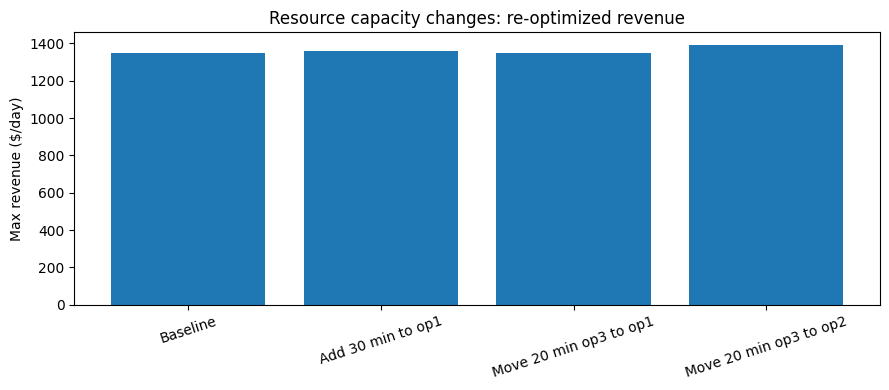

In [10]:
Atbar=np.column_stack([At,np.eye(3)]); toy_basis=[1,2,5]; Bt=Atbar[:,toy_basis]; Bti=np.linalg.inv(Bt)
print('Baseline basis inverse:');display(pd.DataFrame(Bti))
scenarios={'Baseline':bt,'Add 30 min to op1':bt+np.array([30,0,0]),
           'Move 20 min op3 to op1':bt+np.array([20,0,-20]),
           'Move 20 min op3 to op2':bt+np.array([0,20,-20])}
rows=[]
for name,rhs in scenarios.items():
    basic_values=Bti@rhs
    rr=solve_max(ct,At,rhs);assert rr.success
    rows.append({'Scenario':name,'Old basis feasible?':np.all(basic_values>=-1e-8),
                 'Trains':rr.x[0],'Trucks':rr.x[1],'Cars':rr.x[2],'Optimal revenue':-rr.fun})
scenario_df=pd.DataFrame(rows);display(scenario_df)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(scenario_df['Scenario'],scenario_df['Optimal revenue']);ax.set_ylabel('Max revenue ($/day)')
ax.set_title('Resource capacity changes: re-optimized revenue');ax.tick_params(axis='x',rotation=18);plt.tight_layout();plt.show()

**Interpretation.** Moving unused minutes away from operation 3 changes the available capacity without directly changing sales prices. Compare the new revenues and product mixes before deciding where capacity should be reassigned. The old basis can become infeasible even when the complete revised model remains feasible.

## 12. Addition of a new production constraint

### Problem description

A fourth assembly operation is introduced. Each train needs 3 minutes on this operation, and each truck and car needs 1 minute. Daily capacity is 300 minutes. Determine whether this new restriction reduces obtainable revenue.

$$
3x_1+x_2+x_3\leq300.
$$

At the previous optimum, the fourth operation would require $3(0)+100+230=330$ minutes, so the old plan violates this new constraint. The updated LP adds the row shown above to the three original TOYCO inequalities.

In [11]:
extra=np.array([[3.,1.,1.]])
print('New operation minutes at previous plan:',(extra@toy.x).item(),'capacity:',300)
with_op4=solve_max(ct,np.vstack([At,extra]),np.r_[bt,300]);assert with_op4.success
report(with_op4,['Trains','Trucks','Cars'])
print('Lost maximum revenue:',round(-toy.fun+with_op4.fun,6))
assert -with_op4.fun<=-toy.fun+1e-8

New operation minutes at previous plan: 330.0 capacity: 300
Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Variable,Optimal value
0,Trains,0.0
1,Trucks,70.0
2,Cars,230.0


Optimal objective (max): 1290.0


,Capacity slack,Max objective marginal
0,60.0,0.0
1,0.0,1.5
2,140.0,0.0
3,0.0,2.0


Lost maximum revenue: 60.0


**Interpretation.** An additional restrictive constraint cannot improve the maximized objective. The new solution gives the best production quantities with the fourth operation enforced. The loss of revenue measures the economic consequence of this capacity requirement under the modeled assumptions.

## 13. Changes affecting optimality: revised unit revenues

### Problem description

The TOYCO sales team proposes two alternative unit-revenue vectors: (i) train $2, truck $3, car $4; (ii) train $6, truck $3, car $4. Capacities remain unchanged. Determine whether the existing production mix remains optimal in each case.

$$
\begin{aligned}
\max z_A&=2x_1+3x_2+4x_3,\\
\max z_B&=6x_1+3x_2+4x_3.
\end{aligned}
$$

For each proposal, compute $y'=c_B'^TB^{-1}$ and $\bar c'=c'-y'^T\bar A$ for the unchanged basis, then compare against the full LP solution.

In [12]:
for title,newc in [('Price policy A',[2,3,4]),('Price policy B',[6,3,4])]:
    newc=np.array(newc,float); cbar=np.r_[newc,np.zeros(3)]
    shadow=cbar[toy_basis]@Bti
    redcost=cbar-shadow@Atbar
    stays=np.max(redcost)<=1e-8
    rr=solve_max(newc,At,bt);assert rr.success
    print('',title,'unit revenues:',newc)
    print('Dual prices from original basis:',shadow.round(4))
    print('Reduced costs:',redcost.round(4),'Old basis remains optimal?',stays)
    print('New optimal schedule:',rr.x.round(4),'Revenue:',round(-rr.fun,4))

 Price policy A unit revenues: [2. 3. 4.]
Dual prices from original basis: [1.5  1.25 0.  ]
Reduced costs: [-3.25  0.    0.   -1.5  -1.25  0.  ] Old basis remains optimal? True
New optimal schedule: [  0. 100. 230.] Revenue: 1220.0
 Price policy B unit revenues: [6. 3. 4.]
Dual prices from original basis: [1.5  1.25 0.  ]
Reduced costs: [ 0.75  0.    0.   -1.5  -1.25  0.  ] Old basis remains optimal? False
New optimal schedule: [ 10.  102.5 215. ] Revenue: 1227.5


**Interpretation.** A change in revenue coefficients does not invalidate the old schedule's physical feasibility, but it can make its product mix suboptimal. The reduced costs determine whether the current basis still maximizes revenue; if not, a new optimal mix is required.

## 14. Addition of a new economic activity (column)

### Problem description

A new toy model would use 2 minutes of operation 1, 1 minute of operation 2, and 1 minute of operation 3 and yield $6 per unit. Should the plant add this product under the existing capacities?

Let $x_4$ denote new-toy units per day. The revised numerical model is:

$$
\begin{aligned}
\max z&=3x_1+2x_2+5x_3+6x_4\\
x_1+2x_2+x_3+2x_4&\leq430\\
3x_1+2x_3+x_4&\leq460\\
x_1+4x_2+x_4&\leq420\\
x_1,x_2,x_3,x_4&\geq0.
\end{aligned}
$$

At the old optimum, the new column's reduced cost is

$$
\bar c_4=6-y^T\begin{bmatrix}2\\1\\1\end{bmatrix}.
$$

A positive reduced cost indicates possible revenue improvement by introducing the new activity.

In [13]:
new_column=np.array([2.,1.,1.]); rev_new=6.
old_dual=-toy.ineqlin.marginals
reduced_new=rev_new-old_dual@new_column
print('Current resource prices:',old_dual)
print('New product contribution:',rev_new,'Resource opportunity cost:',old_dual@new_column)
print('New column reduced cost:',reduced_new)
aug=solve_max([3,2,5,6],np.column_stack([At,new_column]),bt)
assert aug.success
report(aug,['Trains','Trucks','Cars','New model'])
print('Revenue gain over initial plan:',round(-aug.fun+toy.fun,5))

Current resource prices: [1. 2. 0.]
New product contribution: 6.0 Resource opportunity cost: 4.0
New column reduced cost: 2.0
Solver: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Variable,Optimal value
0,Trains,0.00000
1,Trucks,0.00000
2,Cars,163.33333
3,New model,133.33333


Optimal objective (max): 1616.666667


,Capacity slack,Max objective marginal
0,0.00000,2.33333
1,0.00000,1.33333
2,286.66667,0.00000


Revenue gain over initial plan: 266.66667


## 15. Verification and conclusions

Optimization output should be checked against actual constraints, objective calculations, and duality conditions before being used for operating decisions. The following automated checks cover core cases in the notebook.

In [14]:
assert np.all(A_paint@pr.x<=b_paint+1e-8)
assert np.isclose(c_paint@pr.x,-pr.fun)
assert np.allclose(A_paint.T@y-c_paint,d_slack)
assert np.allclose(B@xb,b_paint)
assert np.isclose(ct@toy.x,-toy.fun)
assert np.all(At@toy.x<=bt+1e-7)
assert np.all(np.vstack([At,extra])@with_op4.x<=np.r_[bt,300]+1e-7)
assert np.isclose(np.array([3,2,5,6])@aug.x,-aug.fun)
print('All primal feasibility, objective, and duality checks passed.')

All primal feasibility, objective, and duality checks passed.


## References and modeling limitations

Hamdy A. Taha, *Operations Research: An Introduction*, 8th edition, Chapter 4, pp. 151–191, with the Reddy Mikks and TOYCO models introduced in earlier chapters. The small dual-Simplex worked tableau is a separate illustrative example.

Linear programming assumes deterministic, linear contributions and divisibility of continuous decision variables. Dual prices and current-basis formulas are local: after sufficiently large parameter changes, the production mix and marginal resource values can change. Continuous solutions are not automatically valid integer schedules.